# Showcase - player visualisations

Every chart in `wyscout.reports.player`, with variations, on Southend United players. Each
section names the function, what it shows and the arguments that change it; the last section
is the data behind them.

## Setup

Reload the `wyscout` package on every cell so edits to it are picked up without restarting the kernel, then load the API credentials and point at the local cache. Nothing here produces output.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()  # CLIENT_ID and CLIENT_SECRET for the Wyscout API, from notebooks/.env
os.environ.setdefault("MONGO_HOST", "localhost")  # every API response is cached in Mongo

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

## IDs and the players

Player ids are looked up from the squad by name with `find_player`, and by position from the
role codes (`GK`, `DF`, `MD`, `FW`), so this notebook keeps working as the squad changes.

In [3]:
from pathlib import Path

from wyscout.ids import SOUTHEND, NATIONAL_LEAGUE, SEASON_2025, SEASON_2026, H_CARDWELL, L_CHAMBERS_PARILLON
from wyscout.data.player import find_player, squad
from wyscout.data.season import season_label
from wyscout.reports import player

SEASON = SEASON_2026
PREV_SEASON = SEASON_2025

IMG_DIR = Path("../imgs")  # saved charts go here (git-ignored)
IMG_DIR.mkdir(exist_ok=True)

players = squad(SOUTHEND, SEASON)
KEEPER = next(p for p in players.values() if p["role"]["code2"] == "GK")["wyId"]
DEFENDER = next(p for p in players.values() if p["role"]["code2"] == "DF")["wyId"]
MIDFIELDER = next(p for p in players.values() if p["role"]["code2"] == "MD")["wyId"]
for pid in (H_CARDWELL, L_CHAMBERS_PARILLON, KEEPER, DEFENDER, MIDFIELDER):
    print(pid, players[pid]["shortName"], players[pid]["role"]["name"])

330285 H. Cardwell Forward
702447 L. Chambers-Parillon Midfielder
967468 J. Duncan Goalkeeper
896621 J. Popoola Defender
850677 S. Kamara Midfielder


## `player.event_map` - one kind of event over a season

One pitch of a player's season. `kind` chooses what is drawn:

| kind | what you see | pitch |
|---|---|---|
| `attempts` | attempts sized by xG with the shooting numbers | attacking half |
| `key_passes` | key passes in red, crosses in blue | attacking half |
| `crosses` | heat map of open-play crosses, red dots for assists, blue crosses for blocked | attacking half |
| `aerial_duels` | headers won (blue, with heat map) and lost (red), with the counts | whole |
| `defensive` | interceptions, defensive duels and fouls | whole |
| `distribution` | every pass as an arrow, accurate ones in red | whole |

`half=` overrides the pitch, `legend=False` drops the key, `save_path=` writes a PNG.

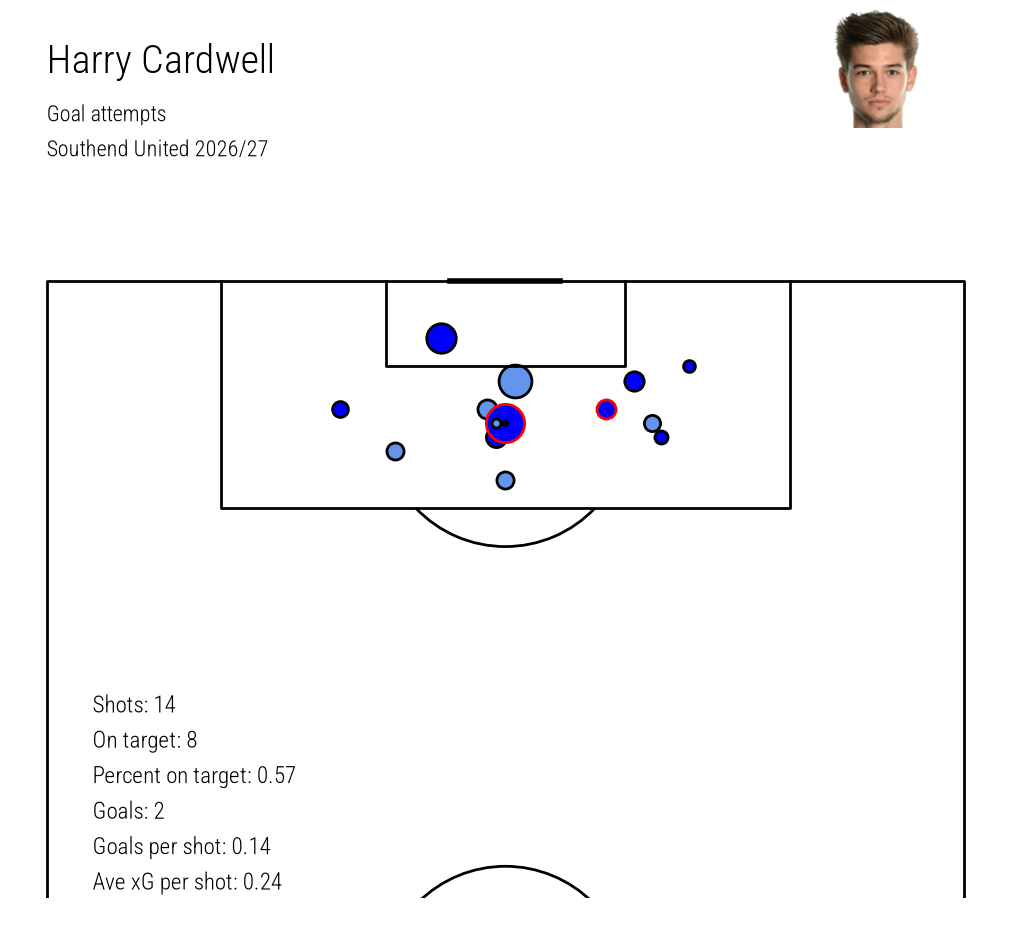

(<Figure size 1125.86x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=2, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=2, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [4]:
player.event_map(H_CARDWELL, SOUTHEND, SEASON, "attempts")

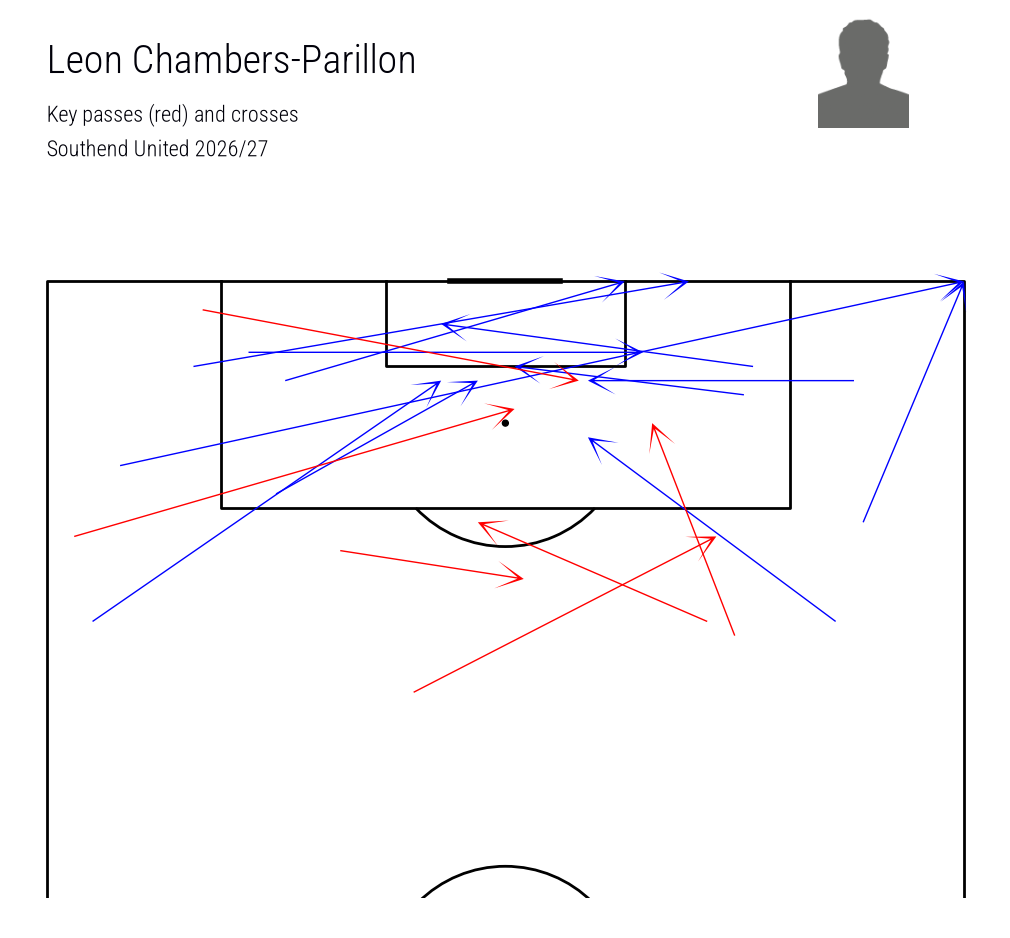

(<Figure size 1125.86x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=2, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=2, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [5]:
player.event_map(L_CHAMBERS_PARILLON, SOUTHEND, SEASON, "key_passes")

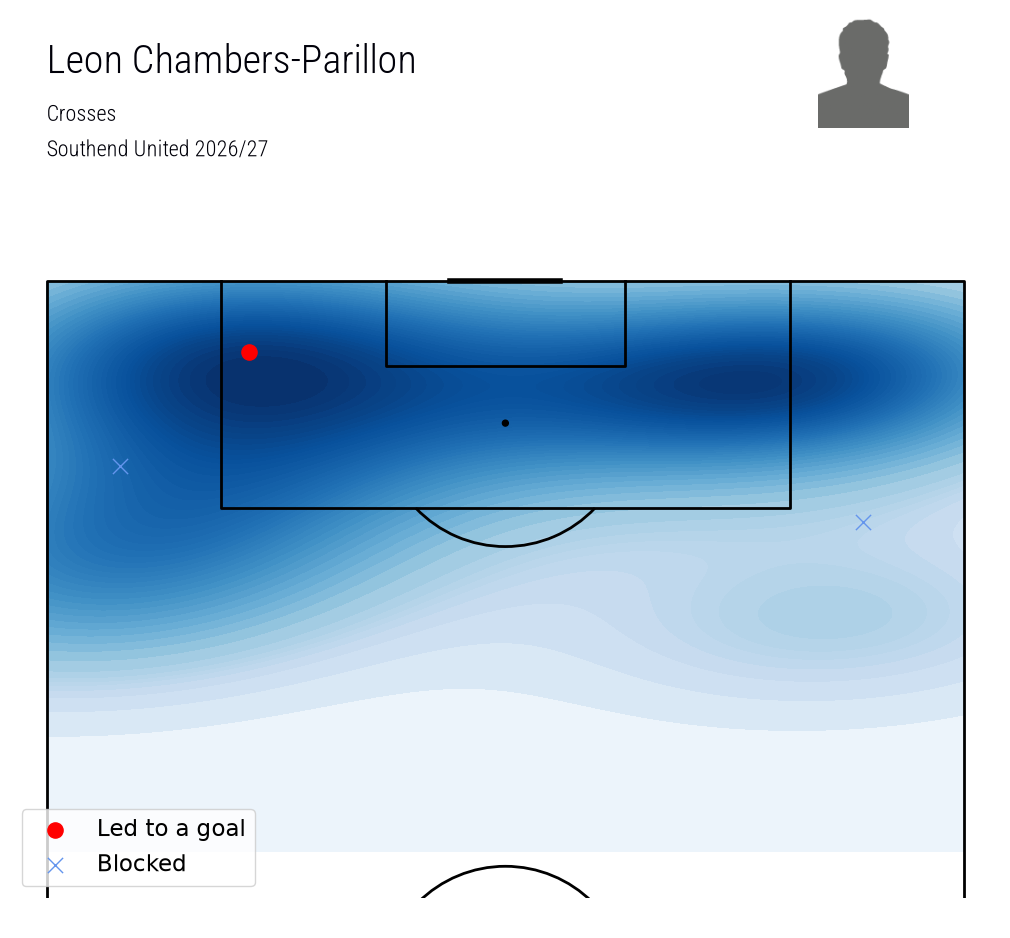

(<Figure size 1125.86x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=2, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=2, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [6]:
player.event_map(L_CHAMBERS_PARILLON, SOUTHEND, SEASON, "crosses")

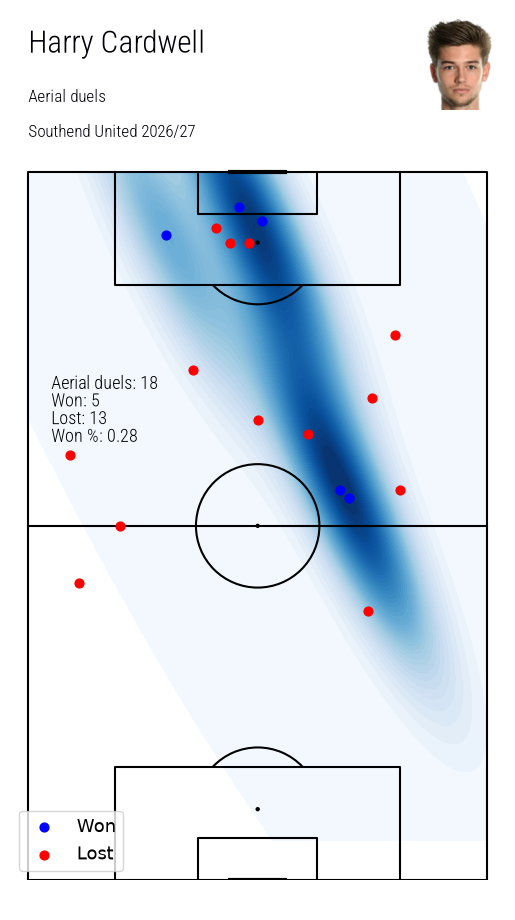

(<Figure size 562.931x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [7]:
player.event_map(H_CARDWELL, SOUTHEND, SEASON, "aerial_duels")

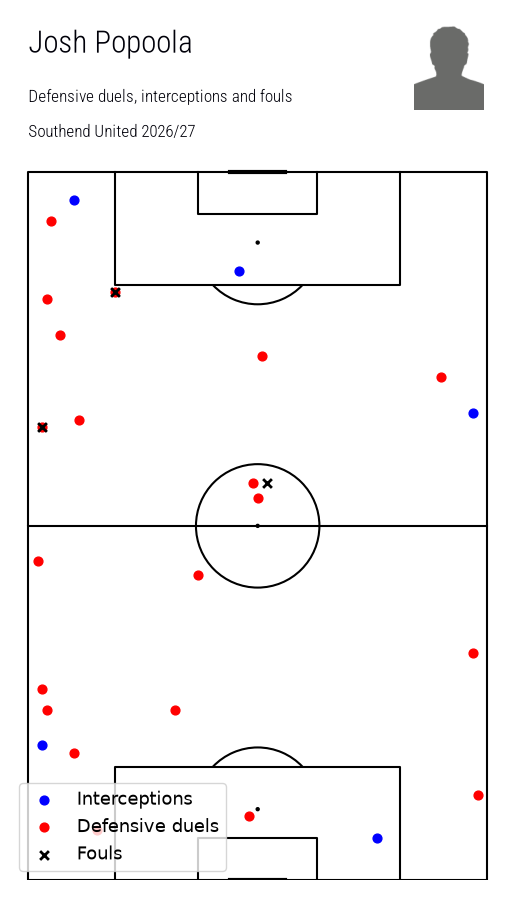

(<Figure size 562.931x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [8]:
player.event_map(DEFENDER, SOUTHEND, SEASON, "defensive")

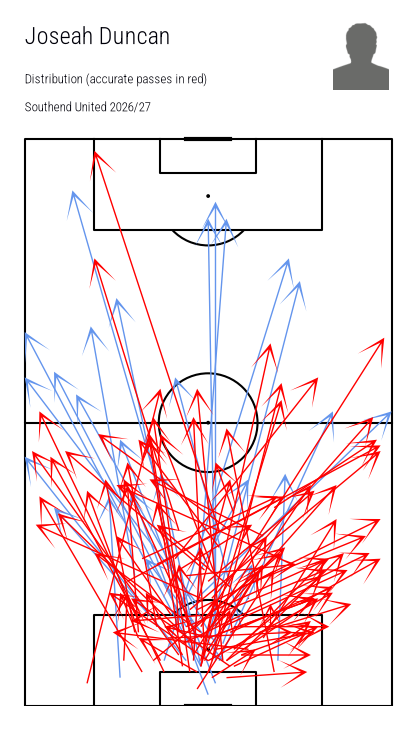

(<Figure size 450.345x800 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [9]:
player.event_map(KEEPER, SOUTHEND, SEASON, "distribution", fig_height=8)

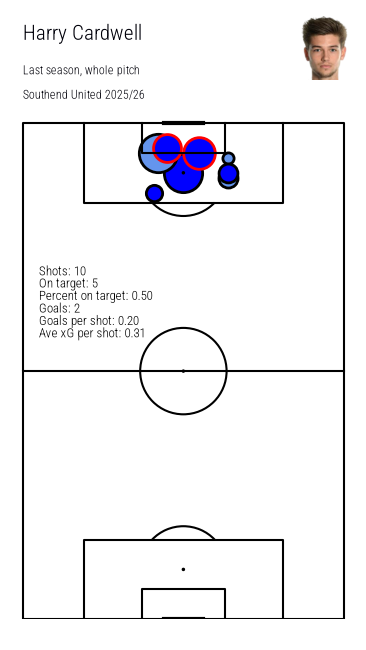

(<Figure size 394.052x700 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [10]:
# variations: the attempts map on the whole pitch, no legend, a smaller figure, saved to disk
player.event_map(H_CARDWELL, SOUTHEND, PREV_SEASON, "attempts", half=False, legend=False, fig_height=7,
                 subtitle="Last season, whole pitch", save_path=IMG_DIR / "cardwell_attempts_2025_26.png")

## `player.comparison` - the same map for several players

Any `kind` from `event_map`, one pitch per `(player_id, team_id, season_id)`. Players can be
from different clubs and seasons; `panel_titles` labels the pitches.

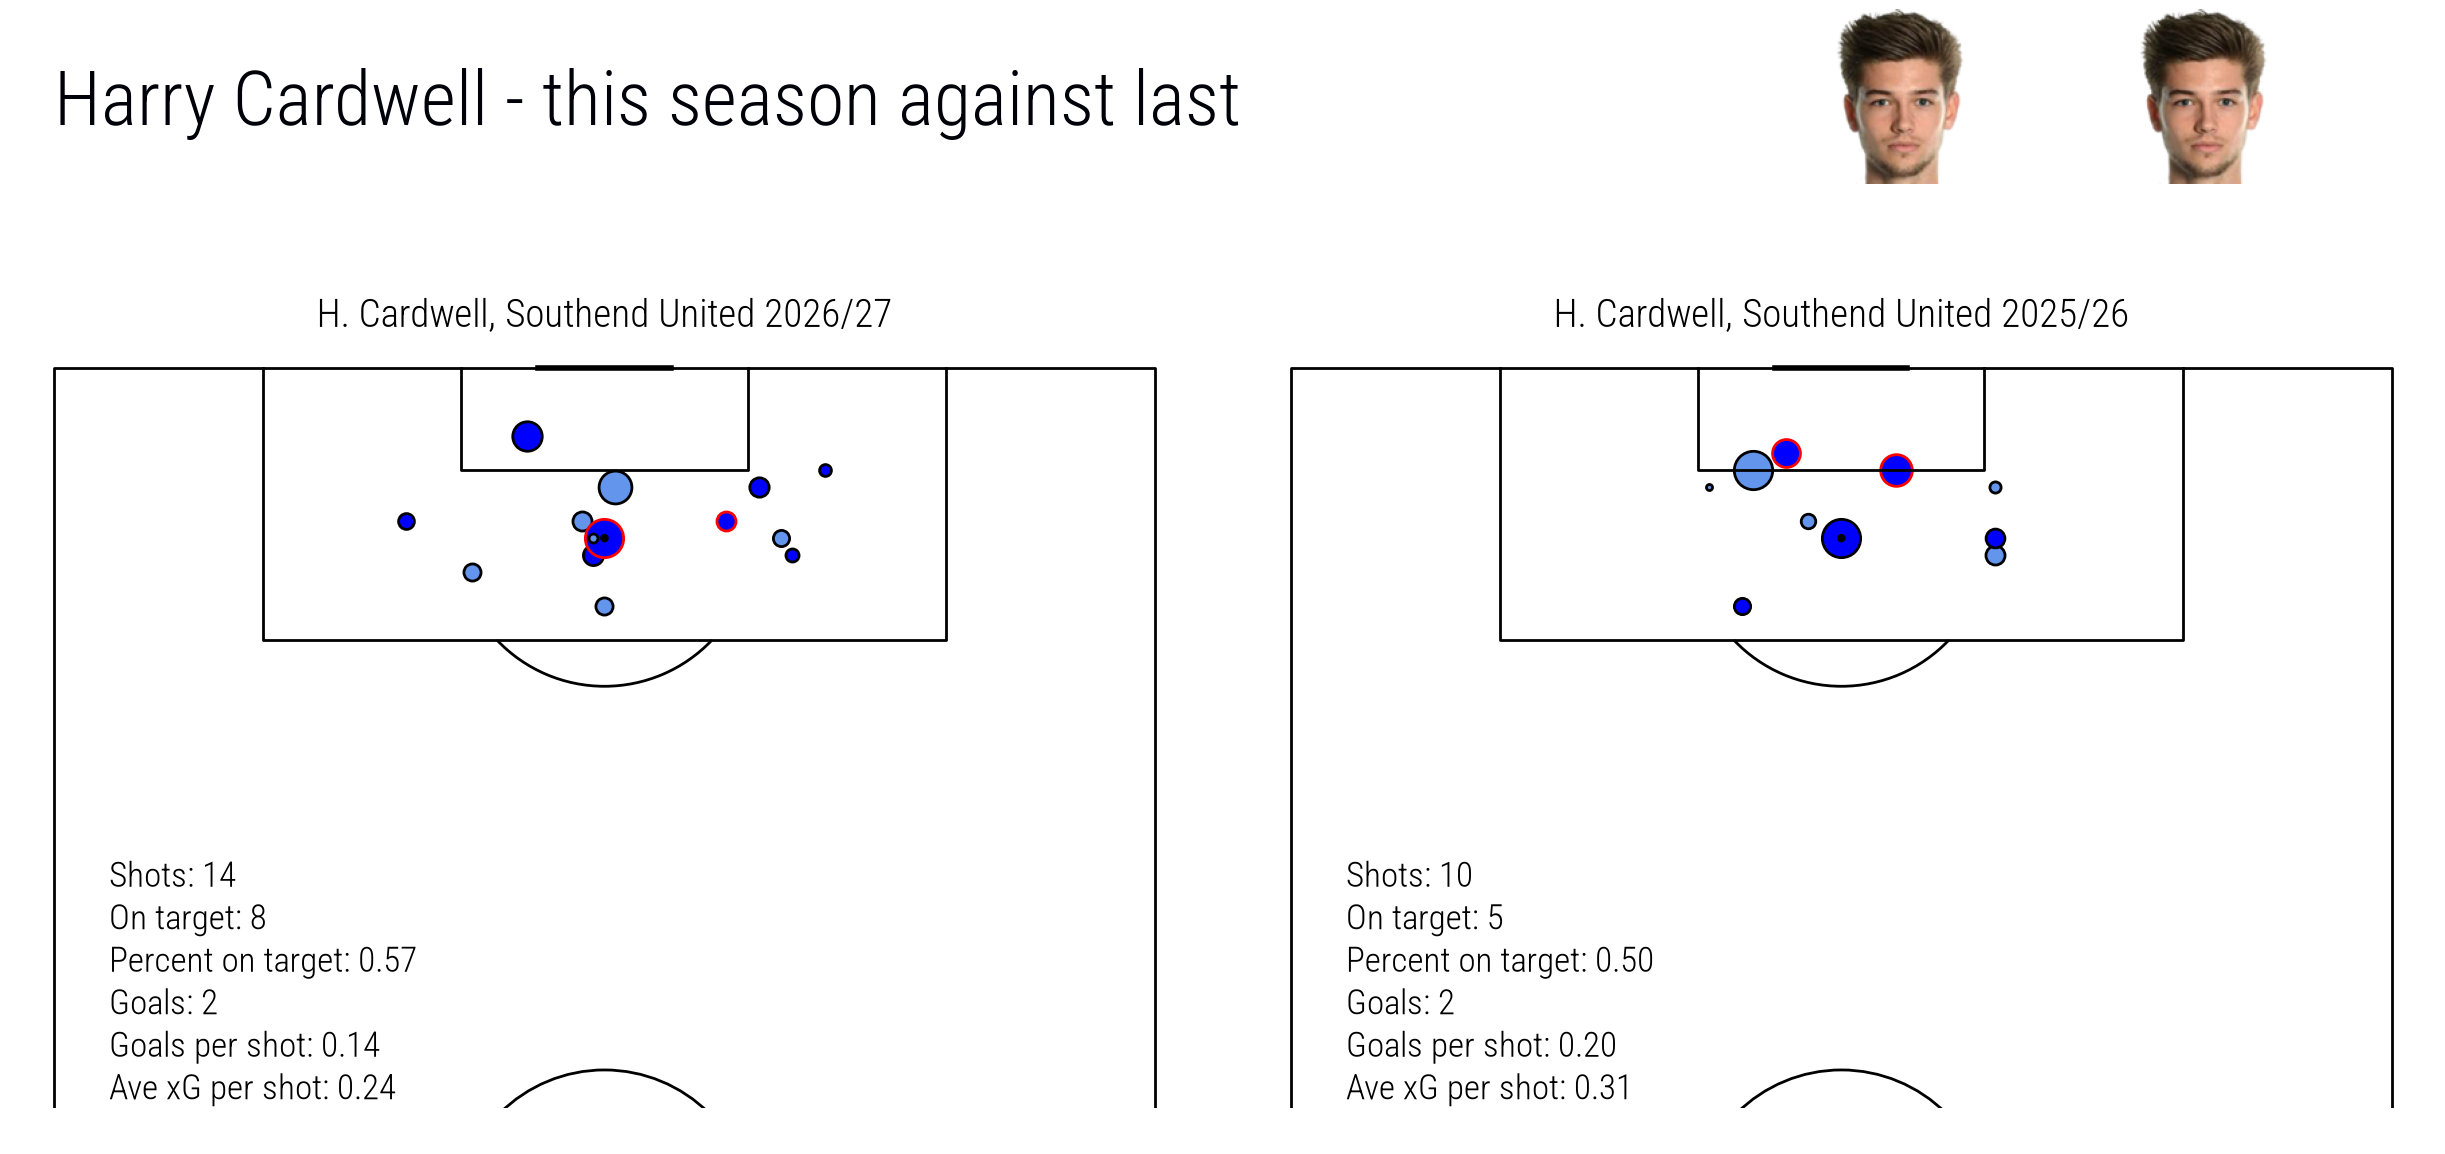

(<Figure size 2756.62x1200 with 6 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=2, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=2, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [11]:
player.comparison([(H_CARDWELL, SOUTHEND, SEASON), (H_CARDWELL, SOUTHEND, PREV_SEASON)], "attempts",
                  "Harry Cardwell - this season against last")

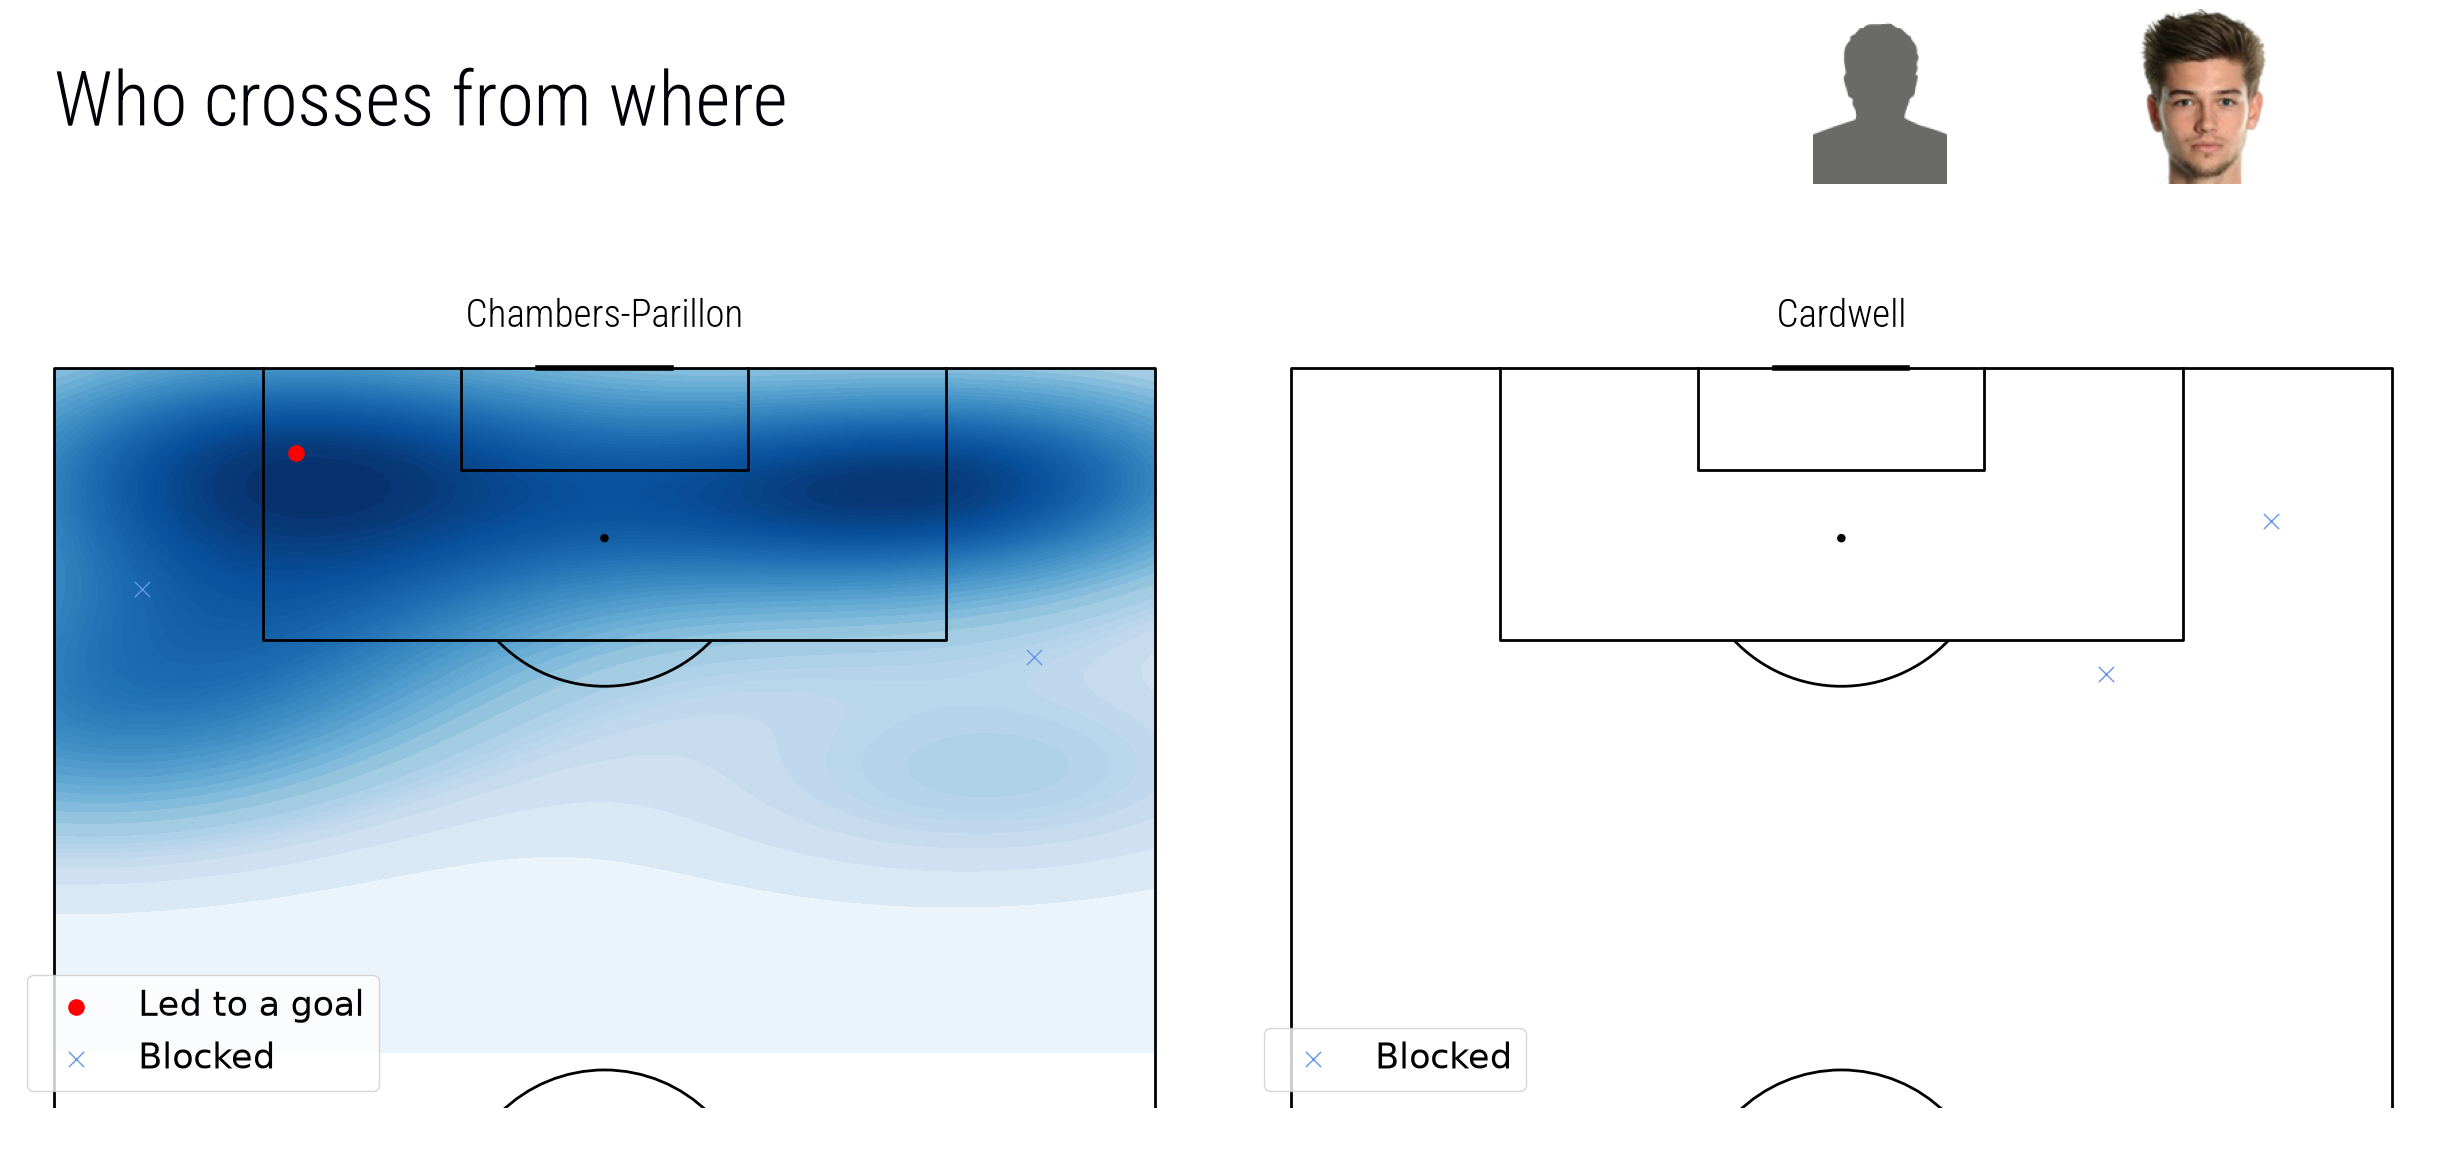

(<Figure size 2756.62x1200 with 6 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=2, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=2, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [12]:
player.comparison([(L_CHAMBERS_PARILLON, SOUTHEND, SEASON), (H_CARDWELL, SOUTHEND, SEASON)], "crosses",
                  "Who crosses from where", panel_titles=["Chambers-Parillon", "Cardwell"])

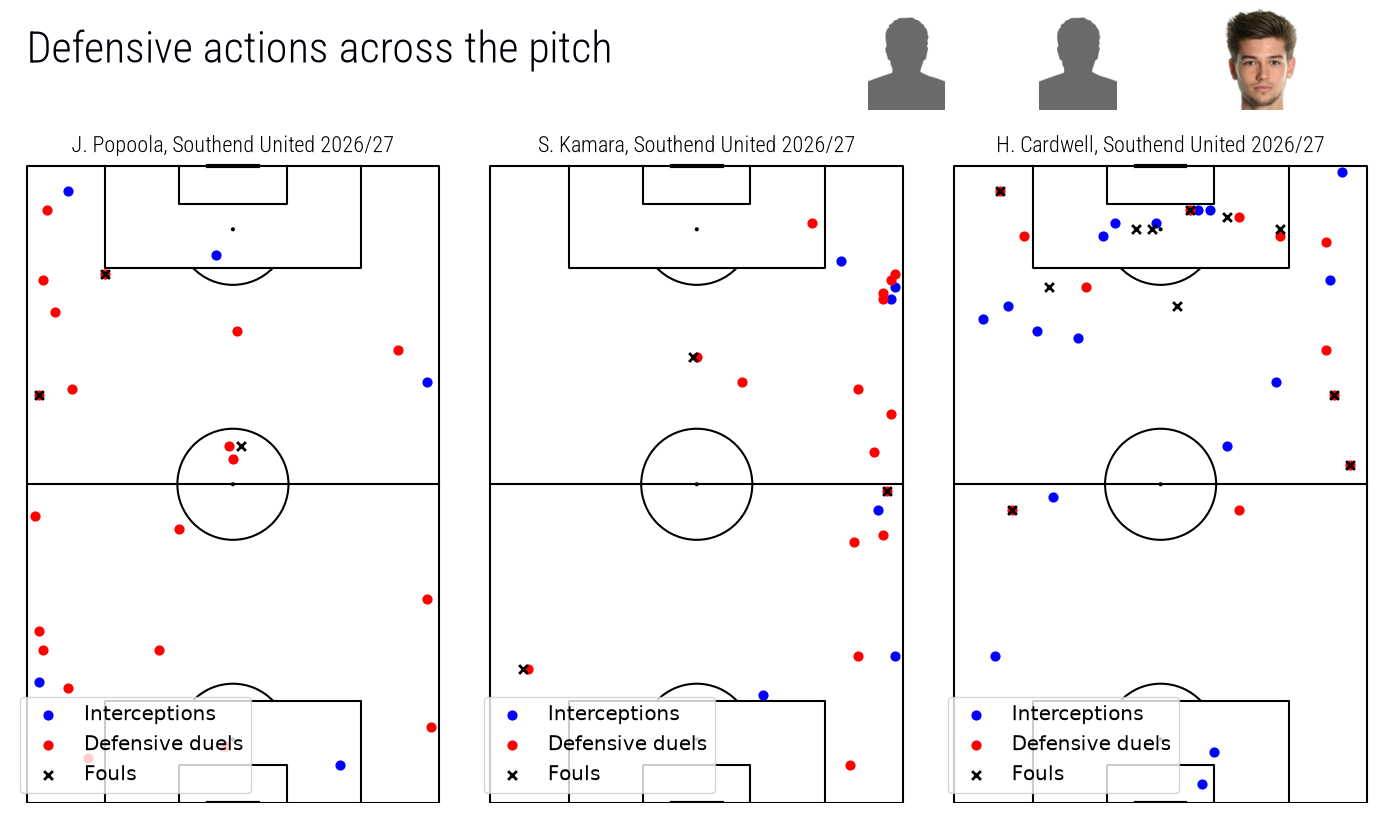

(<Figure size 1560.82x900 with 8 Axes>,
 {'pitch': array([<Axes: >, <Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [13]:
player.comparison([(DEFENDER, SOUTHEND, SEASON), (MIDFIELDER, SOUTHEND, SEASON), (H_CARDWELL, SOUTHEND, SEASON)],
                  "defensive", "Defensive actions across the pitch", fig_height=9)

## `player.passes_received_comparison` - where they get the ball

A heat map of where passes to each player arrived, with their attempts and shooting numbers.

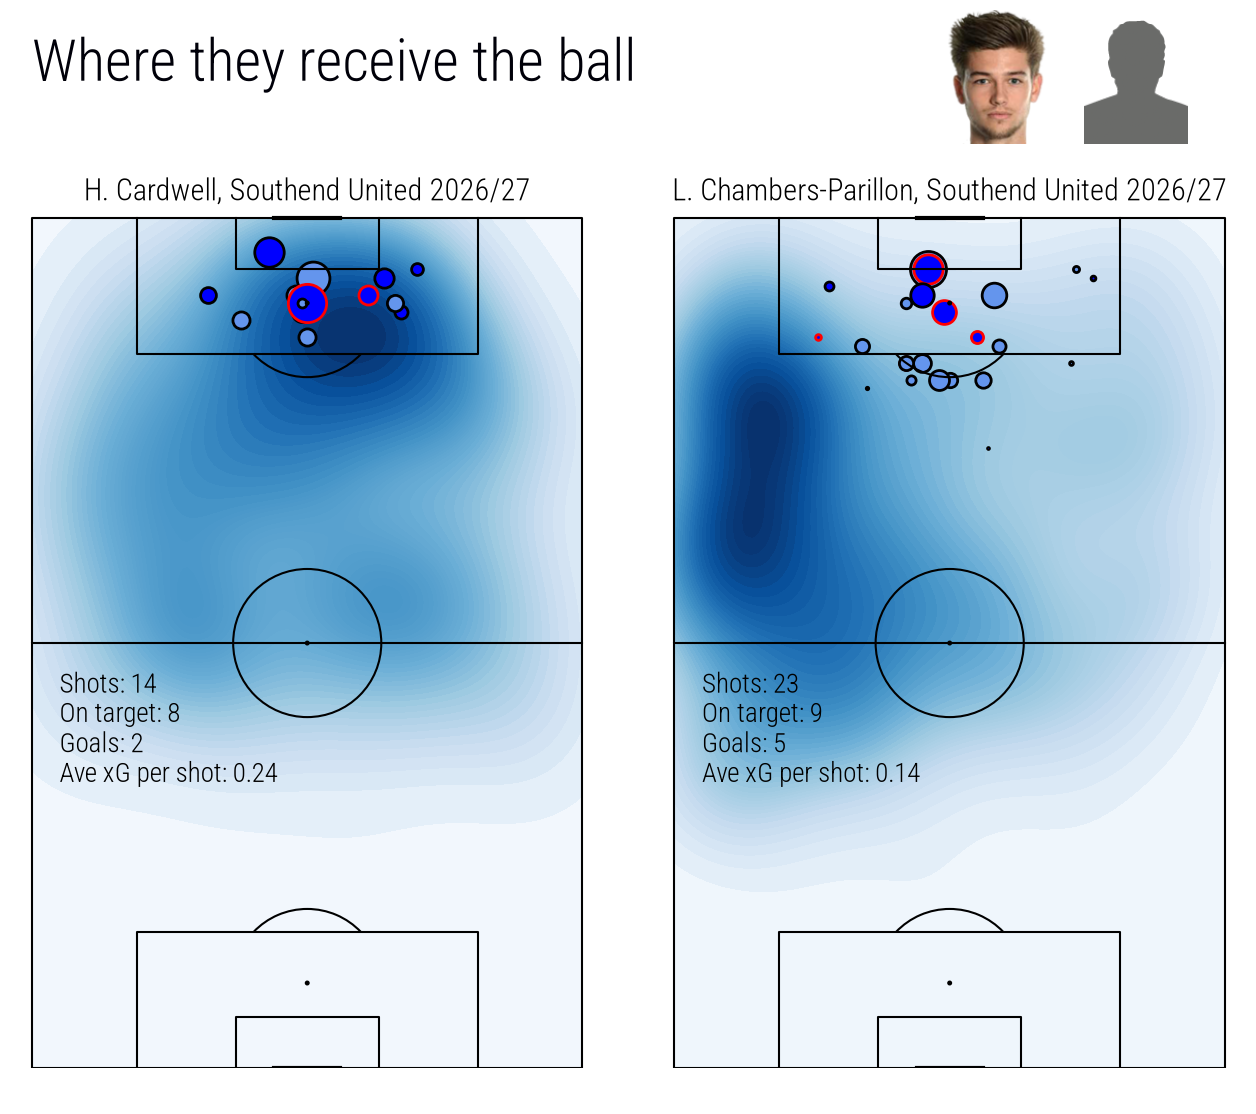

(<Figure size 1405.58x1200 with 6 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1.5, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1.5, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [14]:
player.passes_received_comparison([(H_CARDWELL, SOUTHEND, SEASON), (L_CHAMBERS_PARILLON, SOUTHEND, SEASON)],
                                  "Where they receive the ball")

## `player.season_heat_maps` - a pitch per match

The player's touches in every match they featured in, with attempts marked. `cols` sets the
grid width.

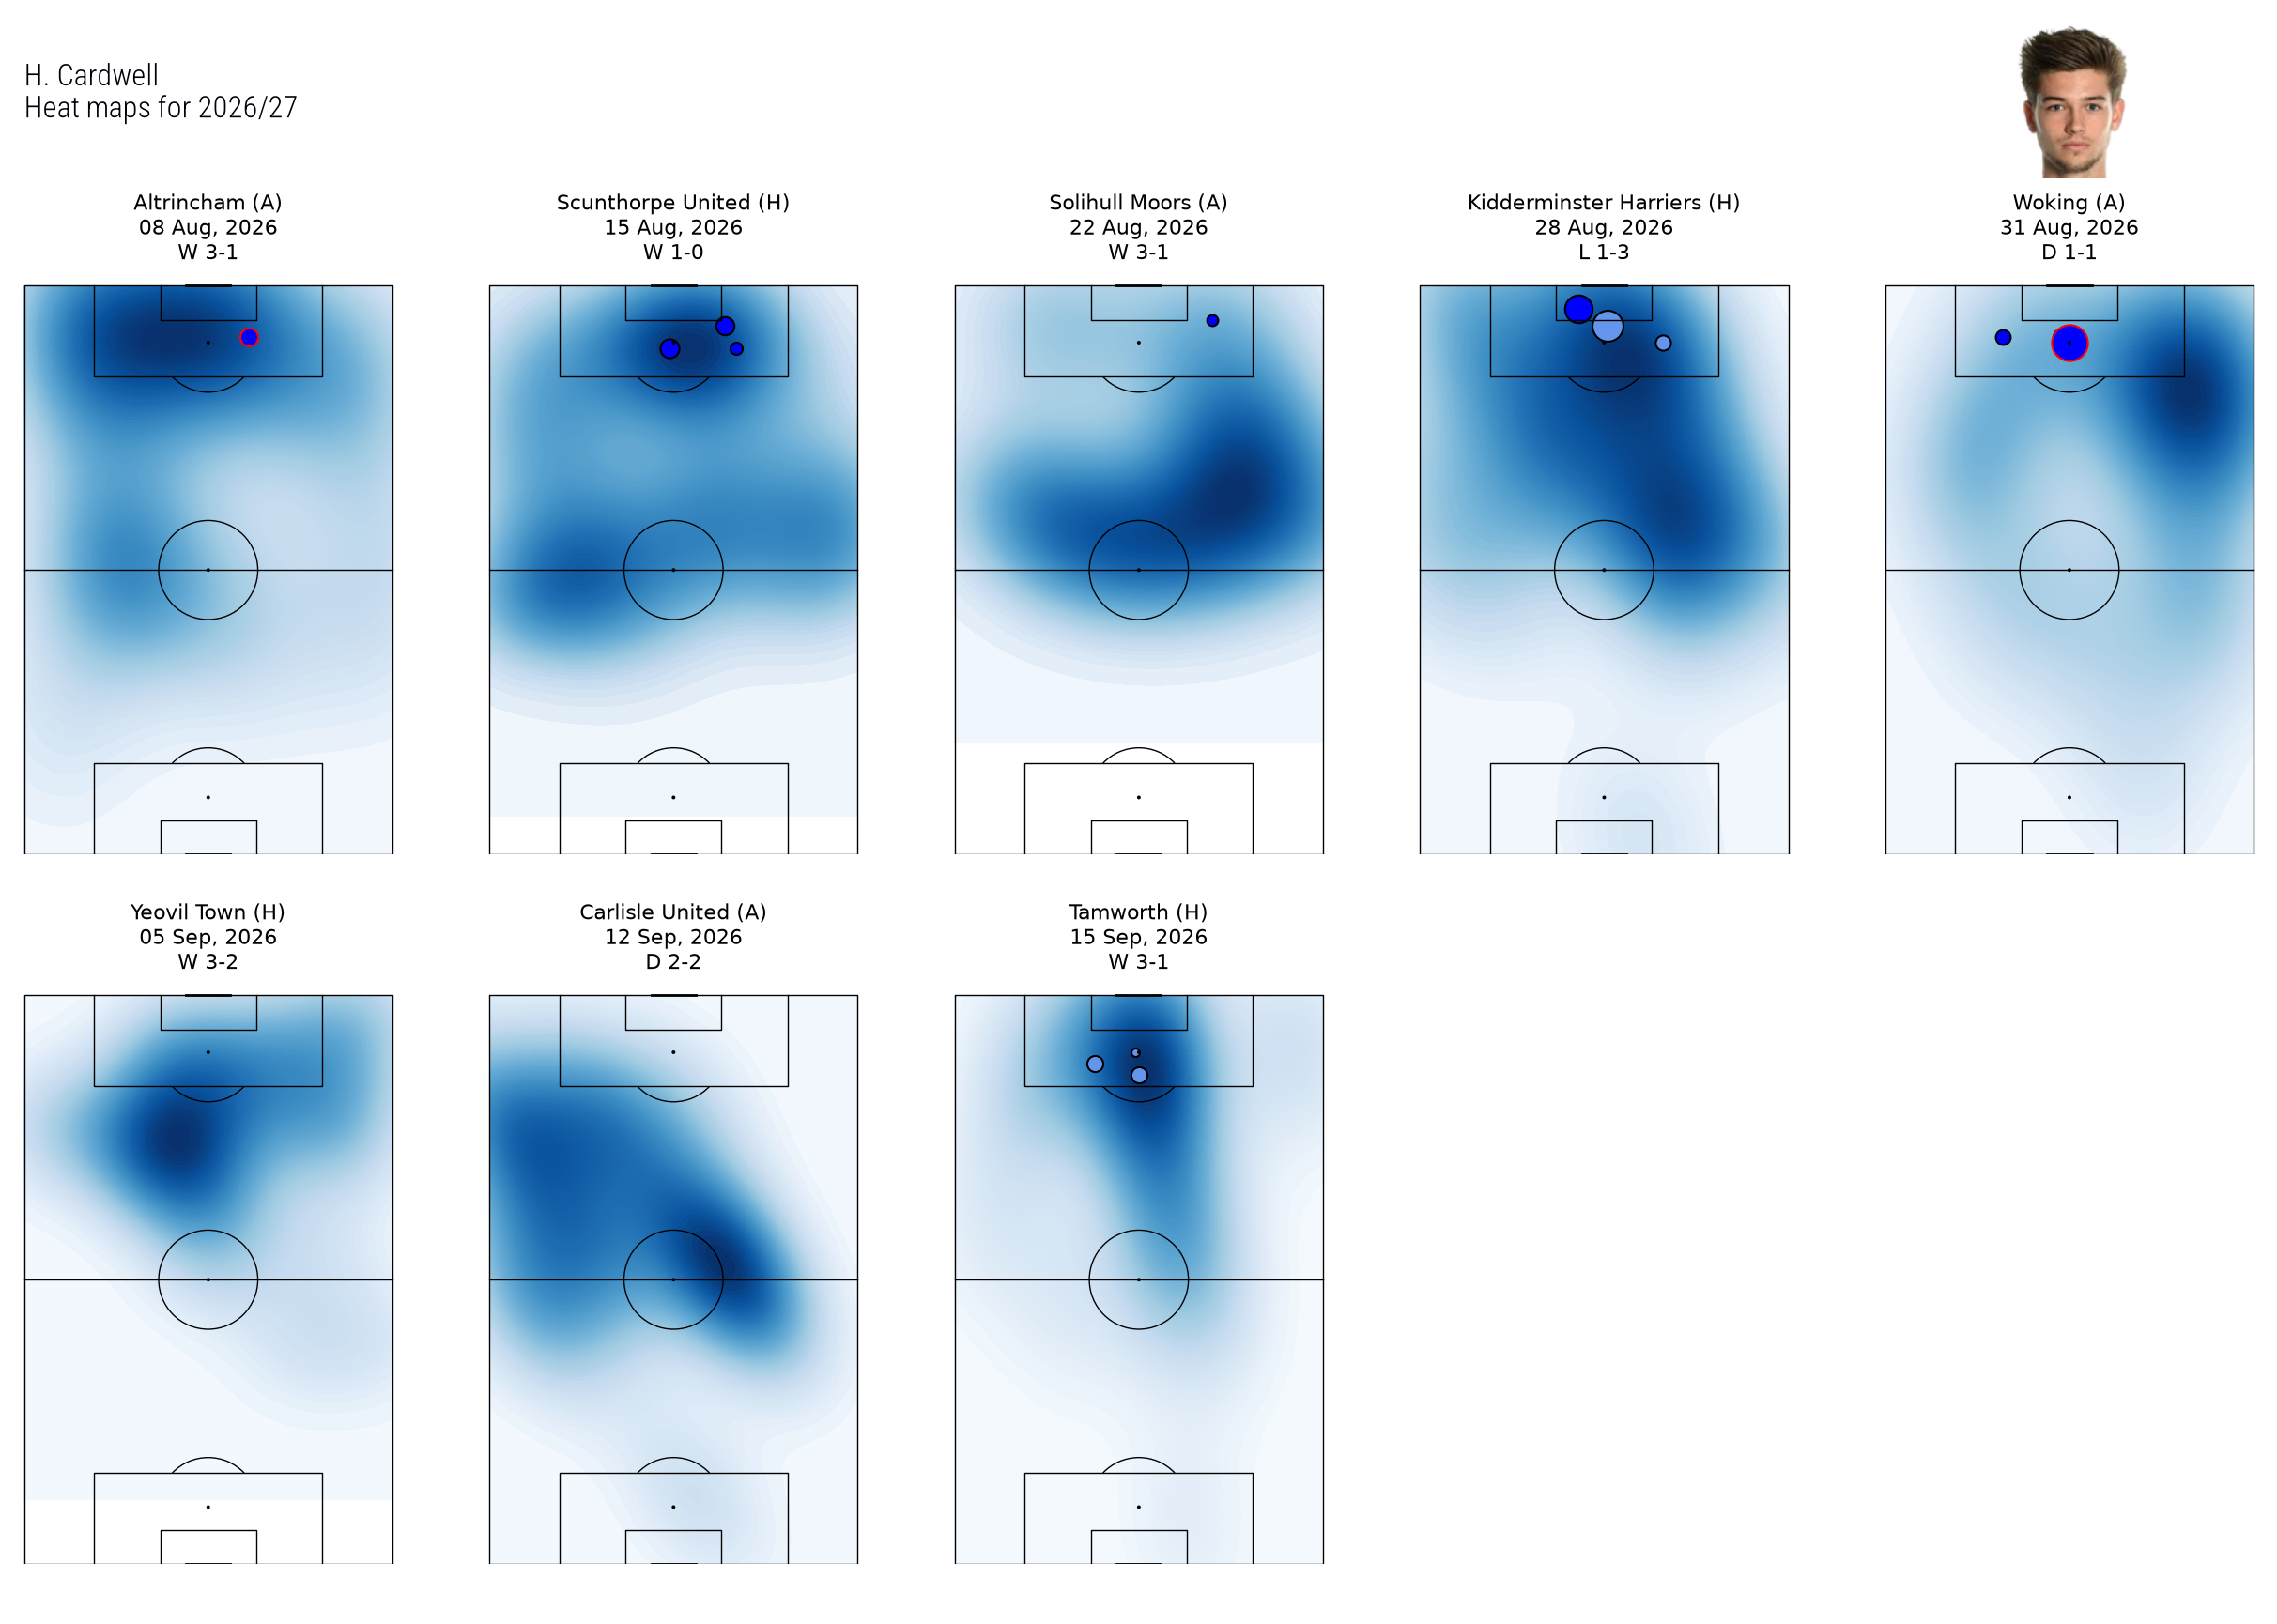

(<Figure size 2733.8x1800 with 13 Axes>,
 {'pitch': array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
         [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [15]:
player.season_heat_maps(H_CARDWELL, SOUTHEND, SEASON, cols=5, fig_height=18)

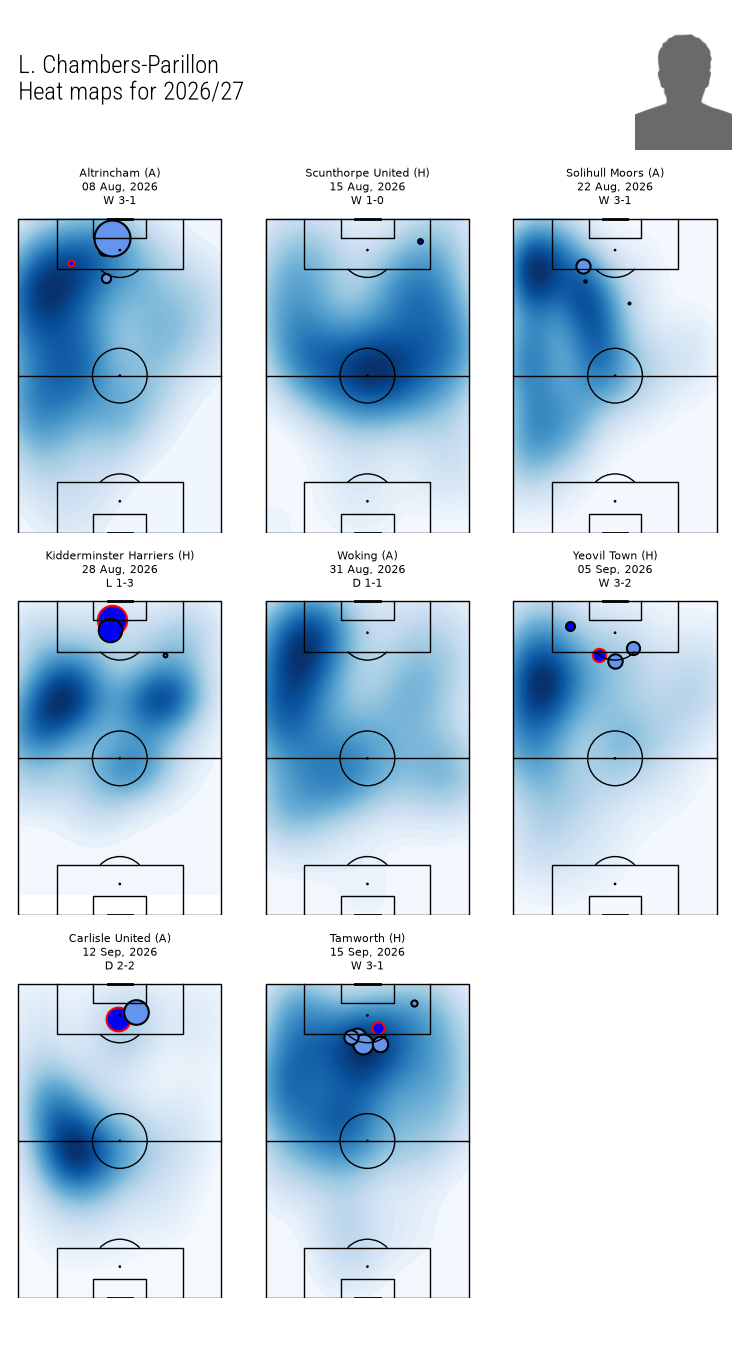

(<Figure size 812.335x1400 with 12 Axes>,
 {'pitch': array([[<Axes: >, <Axes: >, <Axes: >],
         [<Axes: >, <Axes: >, <Axes: >],
         [<Axes: >, <Axes: >, <Axes: >]], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [16]:
player.season_heat_maps(L_CHAMBERS_PARILLON, SOUTHEND, SEASON, cols=3, fig_height=14)

## `player.pass_map` - passes between two players

Every pass from the first player to the second over a season. Low passes dark blue, high
passes light blue, thicker if the move produced a shot.

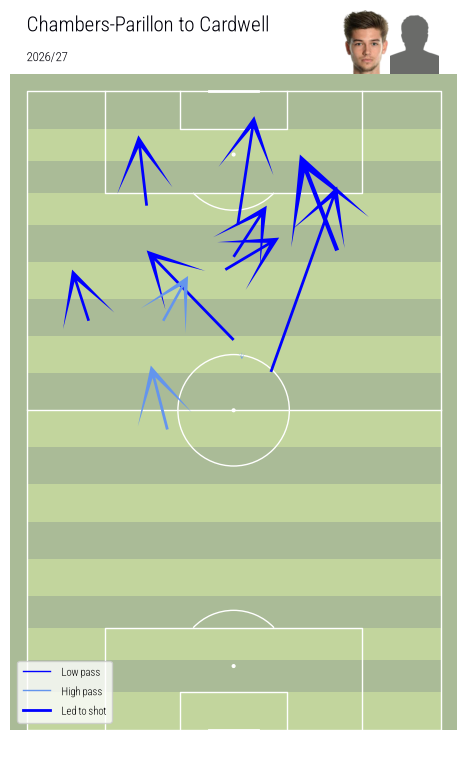

(<Figure size 508.227x800 with 5 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [17]:
player.pass_map(L_CHAMBERS_PARILLON, H_CARDWELL, SOUTHEND, SEASON, subtitle=[season_label(SEASON)])

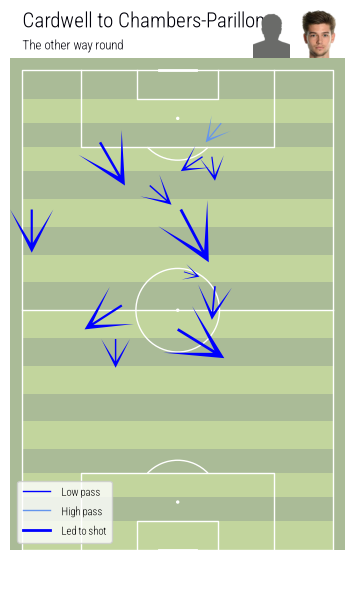

(<Figure size 381.17x600 with 5 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [18]:
player.pass_map(H_CARDWELL, L_CHAMBERS_PARILLON, SOUTHEND, SEASON, subtitle=["The other way round"], fig_height=6)

## `player.distribution_map` - passes made, or received

Every pass the player played as an arrow (accurate in red) over a heat map of where they
played it from; with `received=True`, the passes played to them instead.

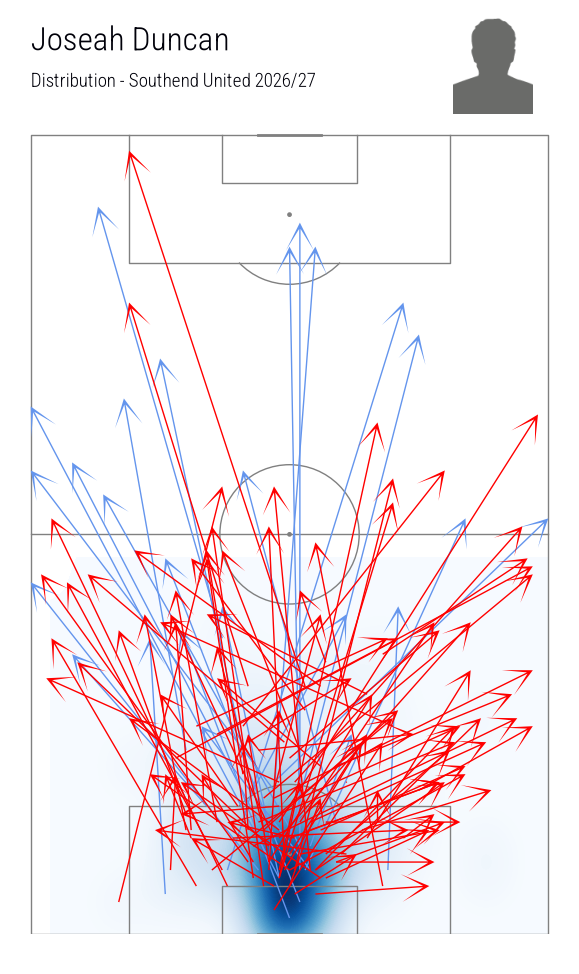

(<Figure size 635.283x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='grey', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [19]:
player.distribution_map(KEEPER, SOUTHEND, SEASON, fig_height=10)

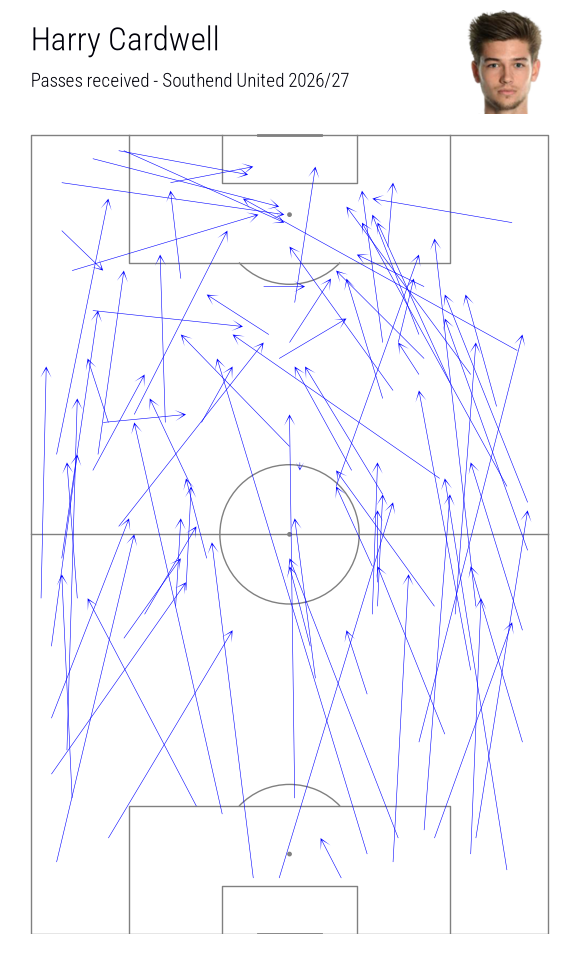

(<Figure size 635.283x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='grey', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [20]:
player.distribution_map(H_CARDWELL, SOUTHEND, SEASON, received=True, fig_height=10)

## `player.attempts_table_chart` - every attempt, as a table

A styled table image with the running xG and the outcome; the data comes back as a DataFrame.

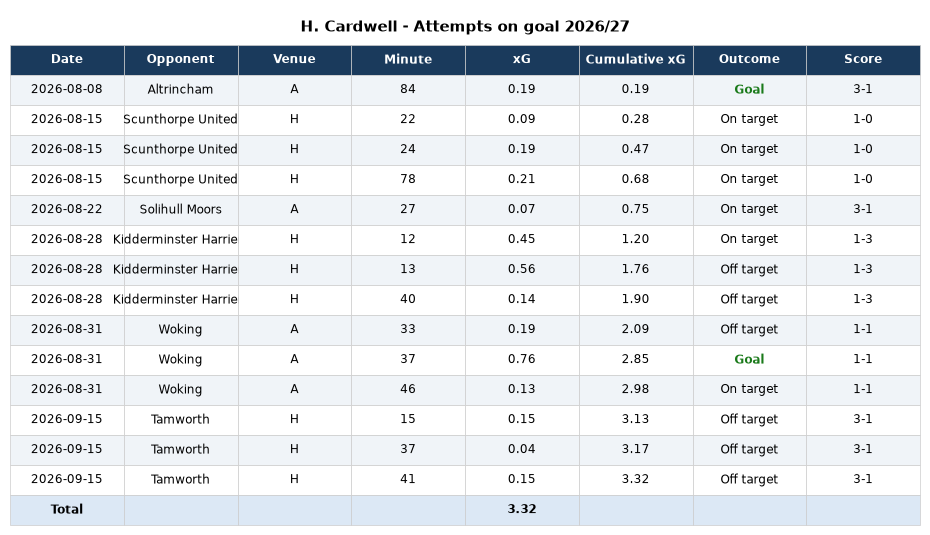

In [21]:
attempts = player.attempts_table_chart(H_CARDWELL, SOUTHEND, SEASON)

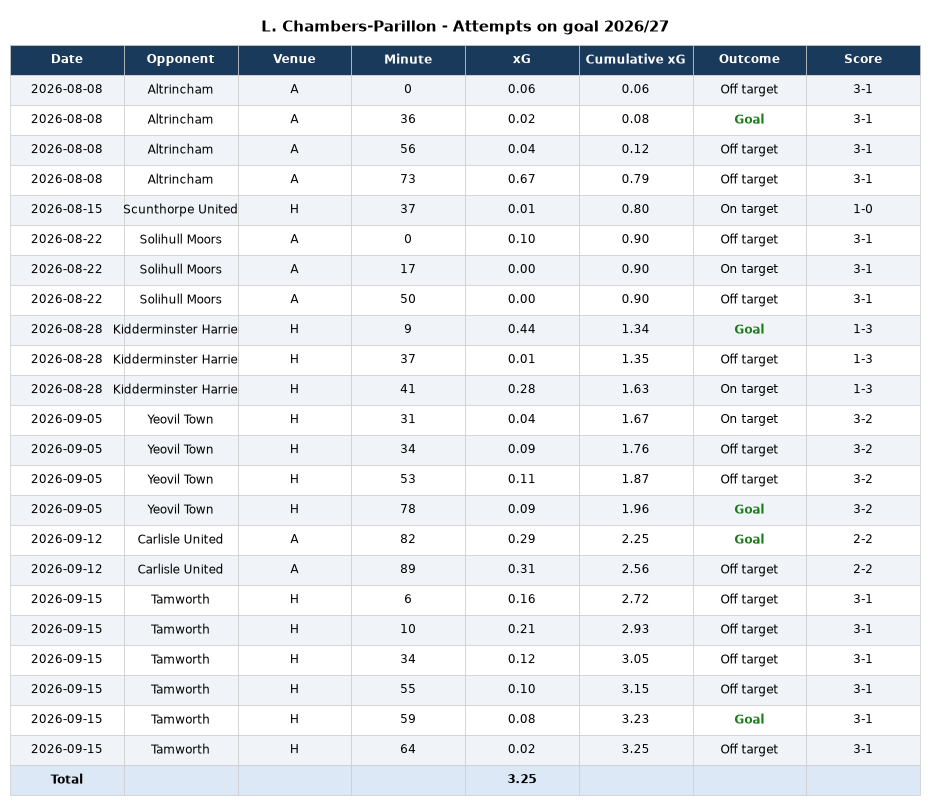

In [22]:
attempts = player.attempts_table_chart(L_CHAMBERS_PARILLON, SOUTHEND, SEASON, save_path=IMG_DIR / "chambers_parillon_attempts.png")

## `player.on_off_pitch` - the team with and without them

The team's attempts split by whether the player was on the pitch, with per-90 rates. Minutes
come from the lineups and substitutions. The player's own attempts are picked out in yellow
unless `highlight_own=False`. The returned dictionary carries the summary table and the goals
scored in each state.

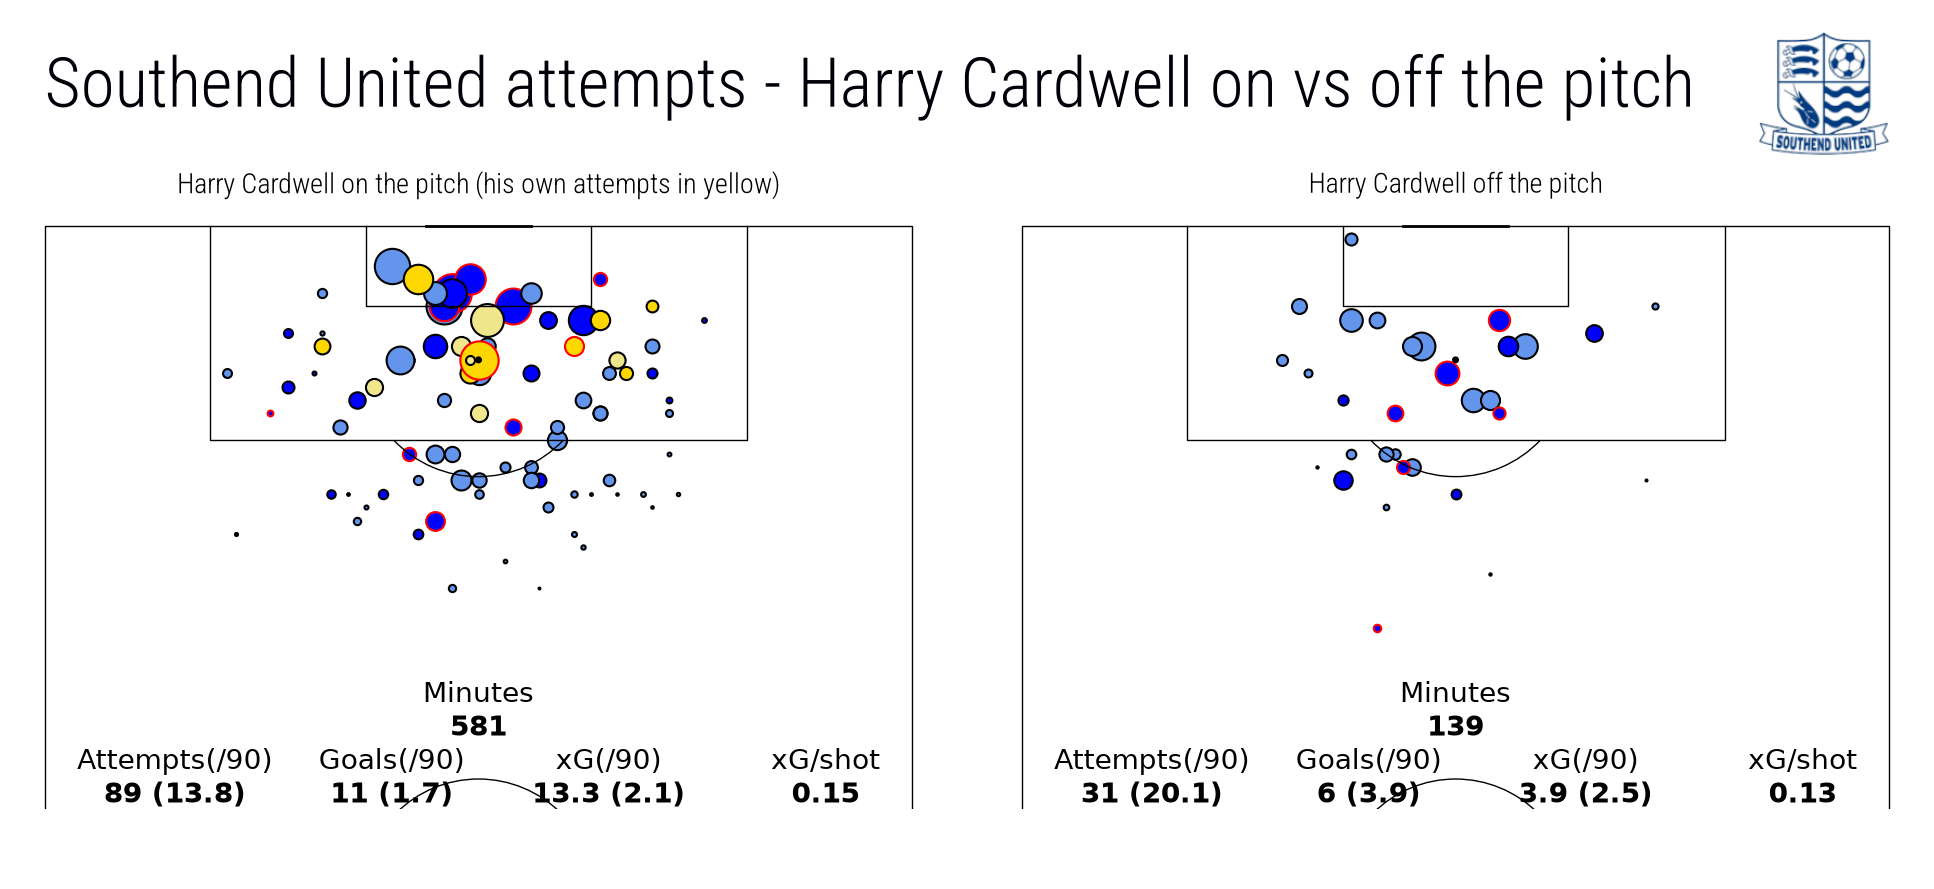

,minutes,shots,on target,xG,goals,shots/90,xG/90,goals/90,xG/shot
,,,,,,,,,
Harry Cardwell on,581,89,38,13.34,11,13.79,2.07,1.70,0.150
Harry Cardwell off,139,31,12,3.93,6,20.07,2.54,3.88,0.127


In [23]:
split = player.on_off_pitch(H_CARDWELL, SOUTHEND, SEASON)
split["summary"]

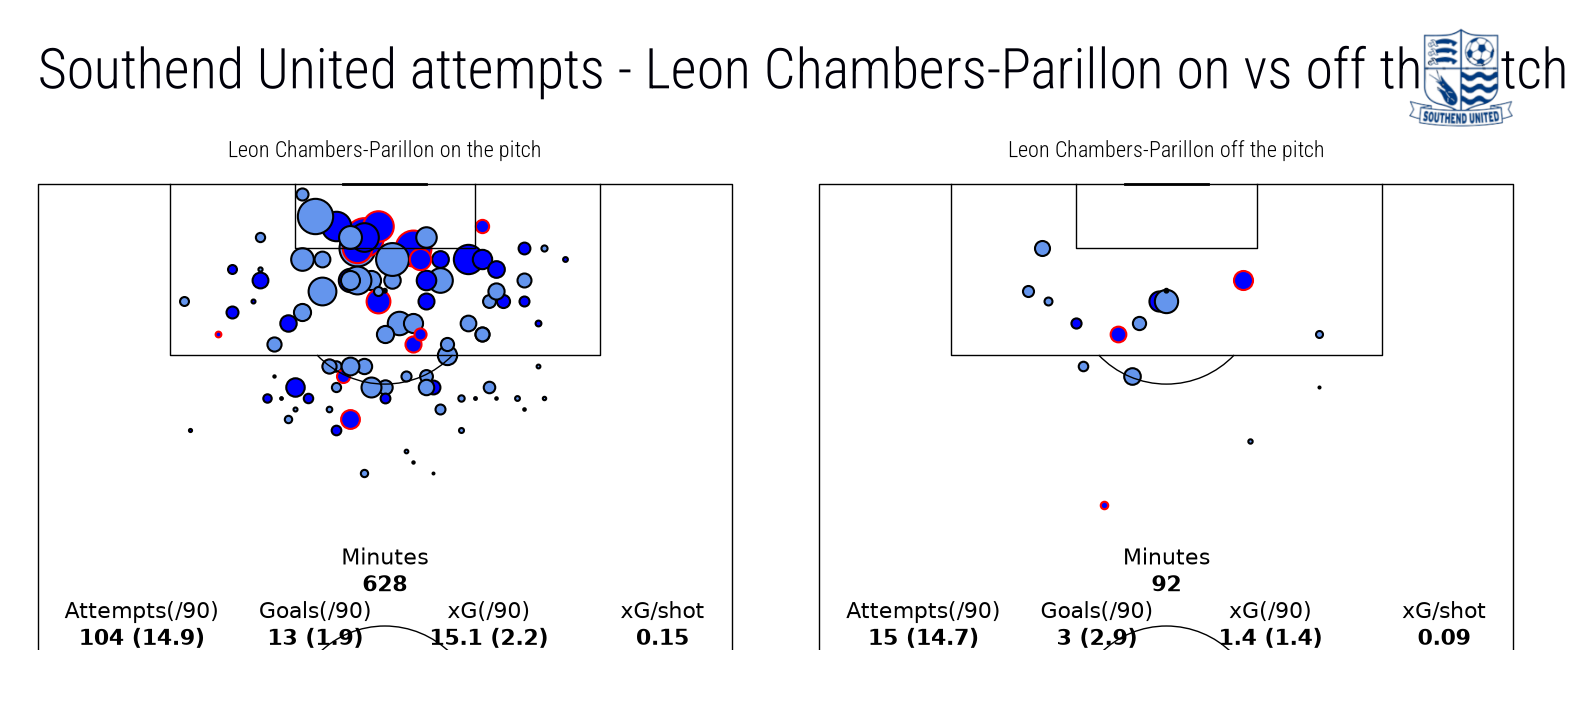

,minutes,shots,on target,xG,goals,shots/90,xG/90,goals/90,xG/shot
,,,,,,,,,
Leon Chambers-Parillon on,628,104,44,15.09,13,14.90,2.16,1.86,0.145
Leon Chambers-Parillon off,92,15,5,1.42,3,14.67,1.39,2.93,0.095


,date,opponent,scorer,min,xG,type
0,2026-08-08,Altrincham (A),H. Cardwell,84,0.19,shot
1,2026-08-22,Solihull Moors (A),C. Kendall,91,0.03,shot
2,2026-09-15,Tamworth (H),S. Austin,81,0.13,shot


In [24]:
split = player.on_off_pitch(L_CHAMBERS_PARILLON, SOUTHEND, SEASON, highlight_own=False, include_pens=False, fig_height=8)
display(split["summary"])
display(split["off"]["goals"])

## The data behind the charts

`wyscout.data.player` fetches and shapes a player's season; `wyscout.data.filters` picks
events out of it. A few of the pieces:

In [25]:
from collections import Counter

from wyscout.data import filters
from wyscout.data.player import attempts_table, minutes_played, player_events, player_spells
from wyscout.data.season import shot_stats
from wyscout.match import get_match_details

events = player_events(H_CARDWELL, SOUTHEND, SEASON)
print("events by type:", Counter(filters.primary(e) for e in events).most_common(6))
print("shooting:", {k: round(v, 2) for k, v in shot_stats(filters.attempts(events, include_pens=True)).items()})

first_match = attempts_table(H_CARDWELL, SOUTHEND, SEASON).iloc[0]
print("first attempt of the season:", dict(first_match))

events by type: [('pass', 67), ('duel', 50), ('interception', 17), ('touch', 15), ('shot', 13), ('infraction', 11)]
shooting: {'shots': 14, 'on_target': 8, 'pct_on_target': 0.57, 'goals': 2, 'goals_per_shot': 0.14, 'xg': 3.32, 'post_shot_xg': 3.02, 'xg_per_shot': 0.24}
first attempt of the season: {'date': '2026-08-08', 'opponent': 'Altrincham', 'venue': 'A', 'score': '3-1', 'minute': np.int64(84), 'xG': np.float64(0.19), 'on_target': np.True_, 'outcome': 'Goal', 'type': 'shot'}


In [26]:
from wyscout.data.season import played_matches

for m in played_matches(SOUTHEND, SEASON)[:3]:
    spells = player_spells(H_CARDWELL, SOUTHEND, get_match_details(m["matchId"]))
    print(m["label"], "->", spells, f"{minutes_played(spells)} minutes")

Altrincham - Southend United, 1-3 -> [(0, 87)] 87 minutes
Southend United - Scunthorpe United, 1-0 -> [(0, 83)] 83 minutes
Solihull Moors - Southend United, 1-3 -> [(0, 74)] 74 minutes
